# DWBI Week 2 · Task 1 — The three tiers, and what a warehouse must be
**Case:** PakFreight · **Evidence files (read-only, never edited):** `marine_shipments.csv`, `rail_shipments.xlsx`, `road_shipments.csv`

**Assumption:** the three tiers are **Source → Warehouse (staging, then storage) → Presentation**. Staging is the first stage of the warehouse tier.

## 1. The three tiers

| Tier | One-line job | One thing that happens in PakFreight | One thing that must not happen there |
|---|---|---|---|
| **Source** | Record operations as they happen. | The rail register records consignment 45017 (Karachi Cantt → Peshawar Cantt) as Delivered. | Report totals mixed in with transactions, like the `TOTAL` row at the bottom of `road_shipments.csv`. |
| **Warehouse** (staging → storage) | Clean, conform, integrate and keep history. | Rail tons × 1000 → kg, duplicate `rd-505` dropped and logged, all three files loaded into one Shipment table. | Overwriting loaded history, or letting users query raw, unconformed staging tables. |
| **Presentation** | Deliver trusted, conformed numbers to users. | A report shows tonnage and cost by mode from the one Shipment table. | Cleaning or redefining data inside the report (e.g. converting units in a visual) — that creates a fourth version of the truth. |

## 2. Inmon's four properties applied to PakFreight

First, the evidence: load the three files read-only and compare how each one describes the same thing.

In [1]:
from pathlib import Path
import pandas as pd

DATA = Path(".") if Path("marine_shipments.csv").exists() else Path("/mnt/user-data/uploads")

# Read-only loads. Source files are never written back.
marine = pd.read_csv(DATA / "marine_shipments.csv", dtype=str, keep_default_na=False)
road   = pd.read_csv(DATA / "road_shipments.csv",   dtype=str, keep_default_na=False)
rail   = pd.read_excel(DATA / "rail_shipments.xlsx", header=2, dtype=object)   # first 2 rows are titles

rail_date = pd.Timestamp(rail.iloc[0, 1])
ev = pd.DataFrame({
    "file":    ["marine_shipments.csv", "rail_shipments.xlsx", "road_shipments.csv"],
    "ID":      [f"{marine.columns[0]} = {marine.iloc[0,0]}", f"{rail.columns[0]} = {rail.iloc[0,0]}", f"{road.columns[0]} = {road.iloc[0,0]}"],
    "date":    [f"text dd/mm/yyyy: {marine.iloc[2,1]}", f"Excel date (serial {(rail_date - pd.Timestamp('1899-12-30')).days})", f"text yyyy-mm-dd: {road.iloc[0,1]}"],
    "weight":  [f"{marine.columns[4]} = {marine.iloc[0,4]} (kg)", f"{rail.columns[4]} = {rail.iloc[0,4]} (tons)", f"{road.columns[4]} = {road.iloc[0,4]} (kg)"],
    "status":  [repr(marine.iloc[1,6]), repr(rail.iloc[3,6]), repr(road.iloc[2,6])],
})
print(ev.to_string(index=False))

print()
print("Same text, two readings:  '03/02/2026' (marine row MR-1003)")
print("  US reading :", pd.to_datetime("03/02/2026", dayfirst=False).date())
print("  UK reading :", pd.to_datetime("03/02/2026", dayfirst=True).date(), " <- correct (3 Feb)")
print()
print("Road tail rows (not shipments):")
print(road.tail(2).to_string(index=False))
print("Duplicate road rows:", road[road.duplicated(keep=False) & (road.trip_id != '')].trip_id.unique().tolist())

                file                     ID                        date                      weight        status
marine_shipments.csv  Shipment_ID = MR-1001 text dd/mm/yyyy: 03/02/2026      Weight_KG = 18000 (kg)  'DELIVERED '
 rail_shipments.xlsx Consignment No = 45012   Excel date (serial 46056) Weight (Tons) = 32.5 (tons)  ' Delivered'
  road_shipments.csv       trip_id = rd-501 text yyyy-mm-dd: 2026-02-02       weight_kg = 6500 (kg) 'in transit '

Same text, two readings:  '03/02/2026' (marine row MR-1003)
  US reading : 2026-03-02
  UK reading : 2026-02-03  <- correct (3 Feb)

Road tail rows (not shipments):
trip_id trip_date from_city to_city weight_kg cost_pkr status
                                                             
  TOTAL                                 83000   652000       
Duplicate road rows: ['rd-505']


| Property | Satisfied — example from this case | Broken — example from this case |
|---|---|---|
| **Subject-oriented** (organised around business subjects, not applications) | The staged table is organised around **Shipment**; mode is just a `SourceSystem` column, so one question covers Marine, Rail and Road. | Each file is organised around its own application: `trip_id` / `Consignment No` / `Shipment_ID`, each with its own columns. Nobody can ask "all shipments" without three different queries. |
| **Integrated** (one consistent format and meaning) | After staging, all 34 rows follow one contract: `RL-45012`-style IDs, `dd-mmm-yyyy` dates, kilograms, status exactly Delivered / In Transit / Delayed. | **IDs:** `MR-1001` vs `45012` (no prefix) vs `rd-501` (lowercase). **Dates:** text dd/mm/yyyy vs Excel date vs text yyyy-mm-dd. **Weight:** rail in **tons**, marine and road in kg. **Status:** `'DELIVERED '`, `' Delivered'`, `'in transit '` — case and hidden spaces differ. |
| **Time-variant** (history kept; every record tied to a time) | Every row has a ship date (e.g. `rd-501` = 2026-02-02), so cost per tonne can be compared by month, and across three years once more history is loaded. | `Status` has no as-of date. Marine `MR-1003` says `IN TRANSIT` with no "since when". When it becomes Delivered, the in-transit period is gone. |
| **Non-volatile** (loaded data is not changed or deleted) | Raw files are loaded into staging as received and never edited; every correction is a separate, logged step. | *Assumption:* a status column in a source system is updated in place (`IN TRANSIT` → `DELIVERED`). A warehouse that copied that behaviour would be volatile. |

## 3. EDW or ODS?

| | Requirement | Answer | Why |
|---|---|---|---|
| a | A dispatcher needs truck positions every 2 minutes | **ODS** | Current, near-real-time operational detail. |
| b | The CFO compares freight cost per tonne-km across three years | **EDW** | Needs integrated, multi-year history. |
| c | A customer service agent checks whether consignment 45017 left today | **ODS** | A current-state lookup of one record. |
| d | The board reviews mode profitability since 2023 | **EDW** | Needs integrated history across all modes. |

## 4. Independent vs dependent data marts

First, the numbers behind the diagrams. Each department applies only its own rule to the same raw files.

In [2]:
m_kg      = pd.to_numeric(marine["Weight_KG"]).sum()
rail_kg   = pd.to_numeric(rail["Weight (Tons)"]).sum() * 1000
road_rows = road[(road.trip_id != "") & (road.trip_id.str.upper() != "TOTAL")]
road_all  = pd.to_numeric(road["weight_kg"], errors="coerce").sum()        # includes the TOTAL row
road_dup  = pd.to_numeric(road_rows[road_rows.duplicated(keep="first")]["weight_kg"]).sum()
road_clean = pd.to_numeric(road_rows.drop_duplicates()["weight_kg"]).sum()

truth = m_kg + rail_kg + road_clean
totals = {
    "Operations (kept TOTAL row)":      m_kg + rail_kg + road_all - road_dup,
    "Finance (rail tons read as kg)":   m_kg + rail_kg / 1000 + road_clean,
    "Sales (kept duplicate rd-505)":    m_kg + rail_kg + road_rows["weight_kg"].astype(float).sum(),
    "Staged truth (one rule set)":      truth,
}
out = pd.DataFrame({"total_kg": totals}).assign(diff_t=lambda d: (d.total_kg - truth) / 1000)
print(out.to_string(float_format=lambda v: f"{v:,.2f}"))
rows = len(marine) + len(rail) + len(road_rows.drop_duplicates())
print(f"\nRows in truth: {rows} (marine {len(marine)} + rail {len(rail)} + road {len(road_rows.drop_duplicates())})")
assert round(truth) == 578650 and rows == 34

                                 total_kg  diff_t
Operations (kept TOTAL row)    661,650.00   83.00
Finance (rail tons read as kg) 283,695.25 -294.95
Sales (kept duplicate rd-505)  584,750.00    6.10
Staged truth (one rule set)    578,650.00    0.00

Rows in truth: 34 (marine 12 + rail 10 + road 12)


Text(10.0, 2.5, '578.65 t\neveryone')

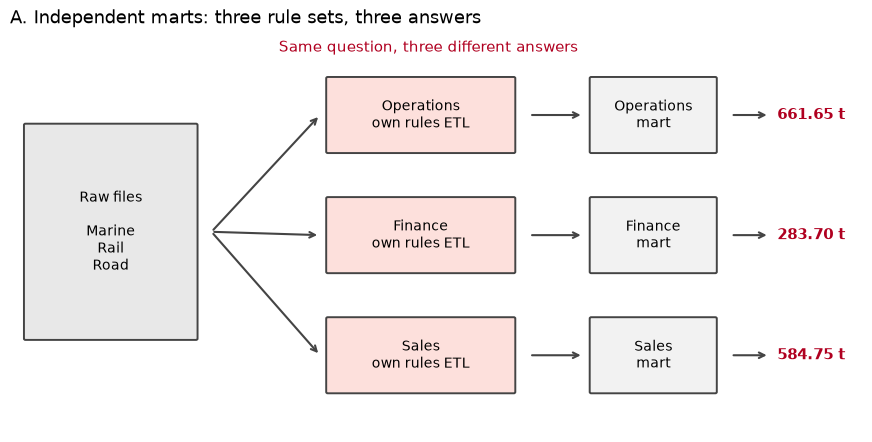

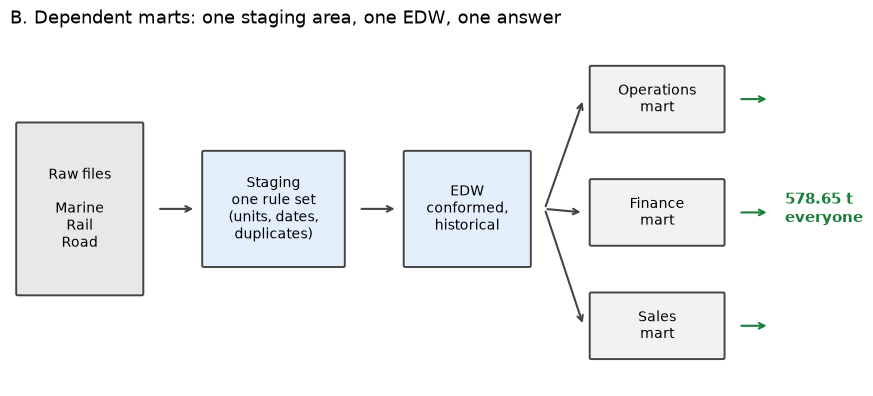

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, w, h, text, fc="#f2f2f2", ec="#444444", fs=10):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec=ec, lw=1.4))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)

def arrow(ax, x1, y1, x2, y2, color="#444444"):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color=color, lw=1.5))

# --- A: independent marts ---
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.set_xlim(0, 11); ax.set_ylim(0, 6); ax.axis("off")
ax.set_title("A. Independent marts: three rule sets, three answers", fontsize=13, loc="left")
box(ax, 0.2, 1.4, 2.2, 3.2, "Raw files\n\nMarine\nRail\nRoad", fc="#e8e8e8")
lanes = [(4.2, "Operations\nown rules", "#fde0dc", f"{totals['Operations (kept TOTAL row)']/1000:,.2f} t"),
         (2.4, "Finance\nown rules",    "#fde0dc", f"{totals['Finance (rail tons read as kg)']/1000:,.2f} t"),
         (0.6, "Sales\nown rules",      "#fde0dc", f"{totals['Sales (kept duplicate rd-505)']/1000:,.2f} t")]
for y, label, color, ans in lanes:
    arrow(ax, 2.6, 3.0, 4.0, y + 0.55)
    box(ax, 4.1, y, 2.4, 1.1, label + " ETL", fc=color)
    arrow(ax, 6.7, y + 0.55, 7.4, y + 0.55)
    box(ax, 7.5, y, 1.6, 1.1, label.split("\n")[0] + "\nmart")
    arrow(ax, 9.3, y + 0.55, 9.8, y + 0.55)
    ax.text(9.9, y + 0.55, ans, va="center", fontsize=11, color="#b00020", fontweight="bold")
ax.text(5.4, 5.7, "Same question, three different answers", ha="center", fontsize=11, color="#b00020")

# --- B: dependent marts ---
fig2, ax2 = plt.subplots(figsize=(11, 4.6))
ax2.set_xlim(0, 11); ax2.set_ylim(0, 5); ax2.axis("off")
ax2.set_title("B. Dependent marts: one staging area, one EDW, one answer", fontsize=13, loc="left")
box(ax2, 0.1, 1.3, 1.6, 2.4, "Raw files\n\nMarine\nRail\nRoad", fc="#e8e8e8")
arrow(ax2, 1.9, 2.5, 2.4, 2.5)
box(ax2, 2.5, 1.7, 1.8, 1.6, "Staging\none rule set\n(units, dates,\nduplicates)", fc="#e3f0fc")
arrow(ax2, 4.5, 2.5, 5.0, 2.5)
box(ax2, 5.1, 1.7, 1.6, 1.6, "EDW\nconformed,\nhistorical", fc="#e3f0fc")
for y, name in [(3.6, "Operations"), (2.0, "Finance"), (0.4, "Sales")]:
    arrow(ax2, 6.9, 2.5, 7.4, y + 0.45)
    box(ax2, 7.5, y, 1.7, 0.9, name + "\nmart")
    arrow(ax2, 9.4, y + 0.45, 9.8, y + 0.45, color="#1b7f3b")
ax2.text(10.0, 2.5, "578.65 t\neveryone", va="center", fontsize=11, color="#1b7f3b", fontweight="bold")

**Why the independent arrangement gives three answers (three sentences):**
Each mart applies its own rules to the same raw files, so each answers a slightly different question: Operations kept the `TOTAL` row (661.65 t), Finance read rail tons as kg (283.70 t) and Sales kept duplicate `rd-505` (584.75 t). With no shared staging area or conformed definitions, no mart can see or correct another's rules. Dependent marts draw only from one staged, conformed EDW, so one rule set gives everyone 578.65 t.

## 5. Why staging?
Raw files pass through staging so units, dates, duplicates and `TOTAL` rows are fixed once, in a logged, repeatable step before they can corrupt the single model, while the raw files stay untouched as evidence.

## 6. We overwrite a customer's old address with the new one
**Property broken:** **non-volatile** (loaded data must not be changed or deleted), and with it **time-variant**, because the history of where the customer was is lost, so old shipments now look as if they went to the new address.

**What the warehouse should have done:** insert a new, time-stamped record for the new address (effective-from date) and close the old record (effective-to date, current flag off). Each shipment then joins to the address that was valid on its ship date.